In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

excel_path = "/kaggle/input/datasets/muratkokludataset/dry-bean-dataset/Dry_Bean_Dataset/Dry_Bean_Dataset.xlsx"
df = pd.read_excel(excel_path, sheet_name="Dry_Beans_Dataset")

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nClass distribution:\n", df["Class"].value_counts())

Shape: (13611, 17)
Missing values: 0
Duplicate rows: 68

Class distribution:
 Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [2]:
X = df.drop(columns=["Class"]).values
y_raw = df["Class"].values

le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_
num_classes = len(class_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("Classes:", dict(enumerate(class_names)))

X_train_scaled: (10888, 16)
X_test_scaled: (2723, 16)
Classes: {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


In [3]:
svm_accs = {}
svm_models = {}

for kernel_name in ["linear", "poly", "rbf"]:
    clf = SVC(kernel=kernel_name, C=1.0, gamma="scale", random_state=42)
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, pred)
    svm_accs[f"SVM ({kernel_name})"] = acc
    svm_models[kernel_name] = clf
    print(f"Kernel = {kernel_name:6s} | Test Accuracy = {acc:.4f}")

best_kernel = max(["linear", "poly", "rbf"], key=lambda k: svm_accs[f"SVM ({k})"])
print("\nBest SVM Kernel:", best_kernel)
print(classification_report(y_test, svm_models[best_kernel].predict(X_test_scaled), target_names=class_names))

Kernel = linear | Test Accuracy = 0.9221
Kernel = poly   | Test Accuracy = 0.9144
Kernel = rbf    | Test Accuracy = 0.9221

Best SVM Kernel: linear
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.90      0.92       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.87      0.86      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



In [5]:
def multiclass_hinge_loss_and_grad(X, y, W, b, reg_lambda=0.01):
    n_samples = X.shape[0]
    scores = X @ W + b
    correct_class_scores = scores[np.arange(n_samples), y][:, np.newaxis]
    margins = np.maximum(0.0, scores - correct_class_scores + 1.0)
    margins[np.arange(n_samples), y] = 0.0

    data_loss = np.sum(margins) / n_samples
    reg_loss = 0.5 * reg_lambda * np.sum(W * W)
    total_loss = data_loss + reg_loss

    grad_mask = (margins > 0).astype(float)
    grad_mask[np.arange(n_samples), y] = -np.sum(grad_mask, axis=1)

    dW = (X.T @ grad_mask) / n_samples + reg_lambda * W
    db = np.sum(grad_mask, axis=0) / n_samples
    return total_loss, dW, db


def predict_minibatch(X, W, b):
    return np.argmax(X @ W + b, axis=1)

In [6]:
OPTIMIZER_NAME = "Mini-Batch GD"
EPOCHS = 120
LR = 0.02
BATCH_SIZE = 256
REG_LAMBDA = 0.01
SEED = 42

rng = np.random.default_rng(SEED)
n_samples, n_features = X_train_scaled.shape

W = rng.normal(0.0, 0.01, size=(n_features, num_classes))
b = np.zeros(num_classes)

loss_history = []
train_acc_history = []
test_acc_history = []

start_time = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    indices = rng.permutation(n_samples)
    for start in range(0, n_samples, BATCH_SIZE):
        batch_idx = indices[start:start + BATCH_SIZE]
        _, dW, db = multiclass_hinge_loss_and_grad(
            X_train_scaled[batch_idx], y_train[batch_idx], W, b, REG_LAMBDA
        )
        W -= LR * dW
        b -= LR * db

    ep_loss, _, _ = multiclass_hinge_loss_and_grad(X_train_scaled, y_train, W, b, REG_LAMBDA)
    loss_history.append(ep_loss)
    train_acc_history.append(accuracy_score(y_train, predict_minibatch(X_train_scaled, W, b)))
    test_acc_history.append(accuracy_score(y_test, predict_minibatch(X_test_scaled, W, b)))

elapsed_time = time.perf_counter() - start_time
y_test_pred_mb = predict_minibatch(X_test_scaled, W, b)

print(f"Optimizer:   {OPTIMIZER_NAME}")
print(f"Batch Size:  {BATCH_SIZE}")
print(f"Final Loss:  {loss_history[-1]:.4f}")
print(f"Train Acc:   {train_acc_history[-1]:.4f}")
print(f"Test Acc:    {test_acc_history[-1]:.4f}")
print(f"Time (sec):  {elapsed_time:.2f}s\n")
print(classification_report(y_test, y_test_pred_mb, target_names=class_names))

Optimizer:   Mini-Batch GD
Batch Size:  256
Final Loss:  0.3468
Train Acc:   0.9216
Test Acc:    0.9170
Time (sec):  1.84s

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.92      0.95      0.93       326
    DERMASON       0.92      0.90      0.91       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.94      0.95      0.94       406
        SIRA       0.84      0.88      0.86       527

    accuracy                           0.92      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723



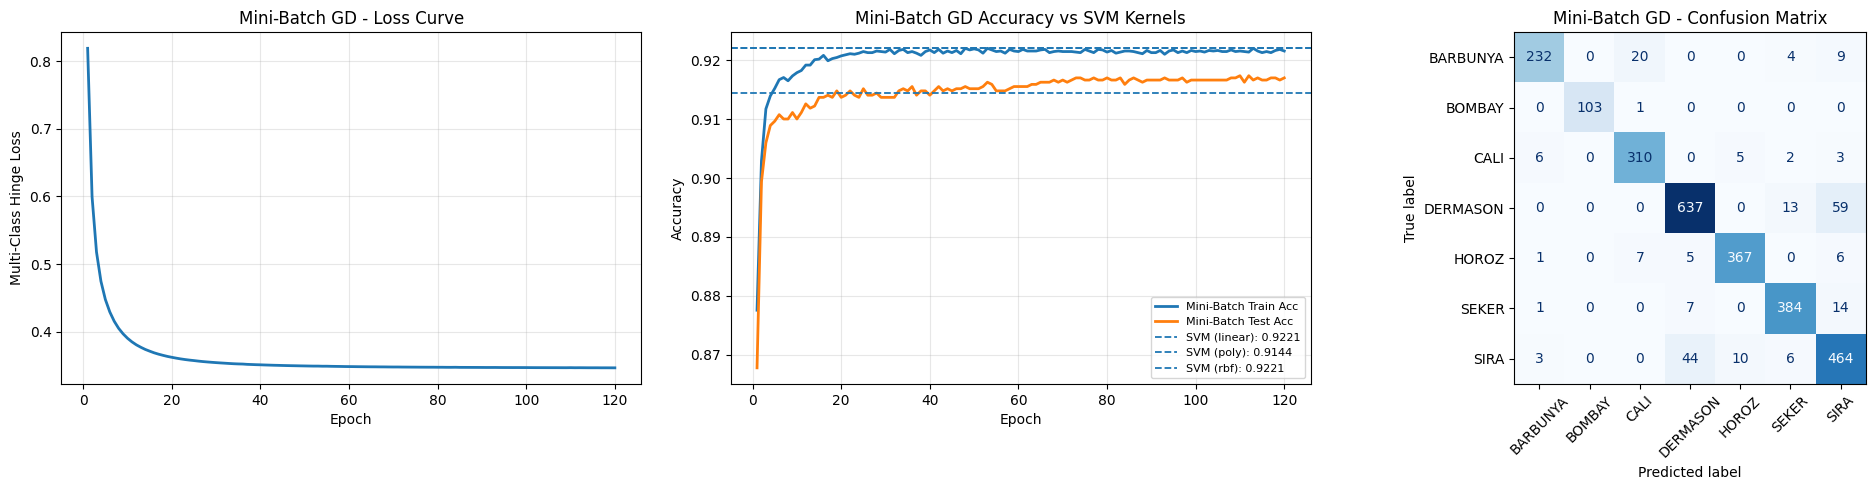

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(range(1, EPOCHS + 1), loss_history, linewidth=2)
axes[0].set_title(f"{OPTIMIZER_NAME} - Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Multi-Class Hinge Loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, EPOCHS + 1), train_acc_history, label="Mini-Batch Train Acc", linewidth=2)
axes[1].plot(range(1, EPOCHS + 1), test_acc_history, label="Mini-Batch Test Acc", linewidth=2)
for k_label, k_score in svm_accs.items():
    axes[1].axhline(k_score, linestyle="--", linewidth=1.3, label=f"{k_label}: {k_score:.4f}")
axes[1].set_title(f"{OPTIMIZER_NAME} Accuracy vs SVM Kernels")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8, loc="lower right")
axes[1].grid(True, alpha=0.3)

cm = confusion_matrix(y_test, y_test_pred_mb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=axes[2], cmap="Blues", xticks_rotation=45, colorbar=False)
axes[2].set_title(f"{OPTIMIZER_NAME} - Confusion Matrix")

plt.tight_layout()
plt.show()